# Figure 7 — Greenberg–Hastings ensemble

The left-hand panels show the mean statistical asymmetry and bands of
one standard deviation on either side of the mean for translations,
reflections, and quarter-turn rotations. The ensemble comprises 3000
runs on a 100 × 100 grid and records generations 0–99. Each cell starts
independently in one of three equally probable states: quiescent (0),
excited (1), or refractory (2). The model updates all cells
simultaneously using four orthogonal neighbours and periodic boundaries.

The right-hand panels show a representative trajectory at generations
0, 50, and 100. The notebook generates the initial grid with NumPy seed
`55` and evolves it through 100 updates.

To generate the input aggregates, run from the repository root:

```bash
julia --startup-file=no scripts/random_evolution_simulate.jl full ghm
```

The script writes `Bdata.txt` and `VBdata.txt` to
`outputs/figure07_full/`. These files contain the sums and sums of
squares of the asymmetry scores across runs at each recorded generation.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Support starting the notebook from the repository root or notebooks/.
output_dir = Path("outputs/figure07_full")
if not output_dir.is_dir():
    output_dir = Path("../outputs/figure07_full")

runs = 3000
totals = np.loadtxt(output_dir / "Bdata.txt")
squared_totals = np.loadtxt(output_dir / "VBdata.txt")

assert totals.shape == squared_totals.shape == (5, 100)
assert np.isfinite(totals).all() and np.isfinite(squared_totals).all()

mean = totals / runs
variance = squared_totals / runs - mean**2
assert (variance >= -1e-12).all()
std = np.sqrt(np.maximum(variance, 0))
time = np.arange(mean.shape[1])

def ghm_step(grid):
    excited = grid == 1
    excited_neighbour = (
        np.roll(excited, 1, axis=0)
        | np.roll(excited, -1, axis=0)
        | np.roll(excited, 1, axis=1)
        | np.roll(excited, -1, axis=1)
    )

    next_grid = np.zeros_like(grid)
    next_grid[(grid == 0) & excited_neighbour] = 1
    next_grid[excited] = 2
    return next_grid

rng = np.random.default_rng(55)
snapshot_steps = (0, 50, 100)
grid = rng.integers(0, 3, size=(100, 100))
snapshots = {0: grid.copy()}

for step in range(1, snapshot_steps[-1] + 1):
    grid = ghm_step(grid)
    if step in snapshot_steps:
        snapshots[step] = grid.copy()

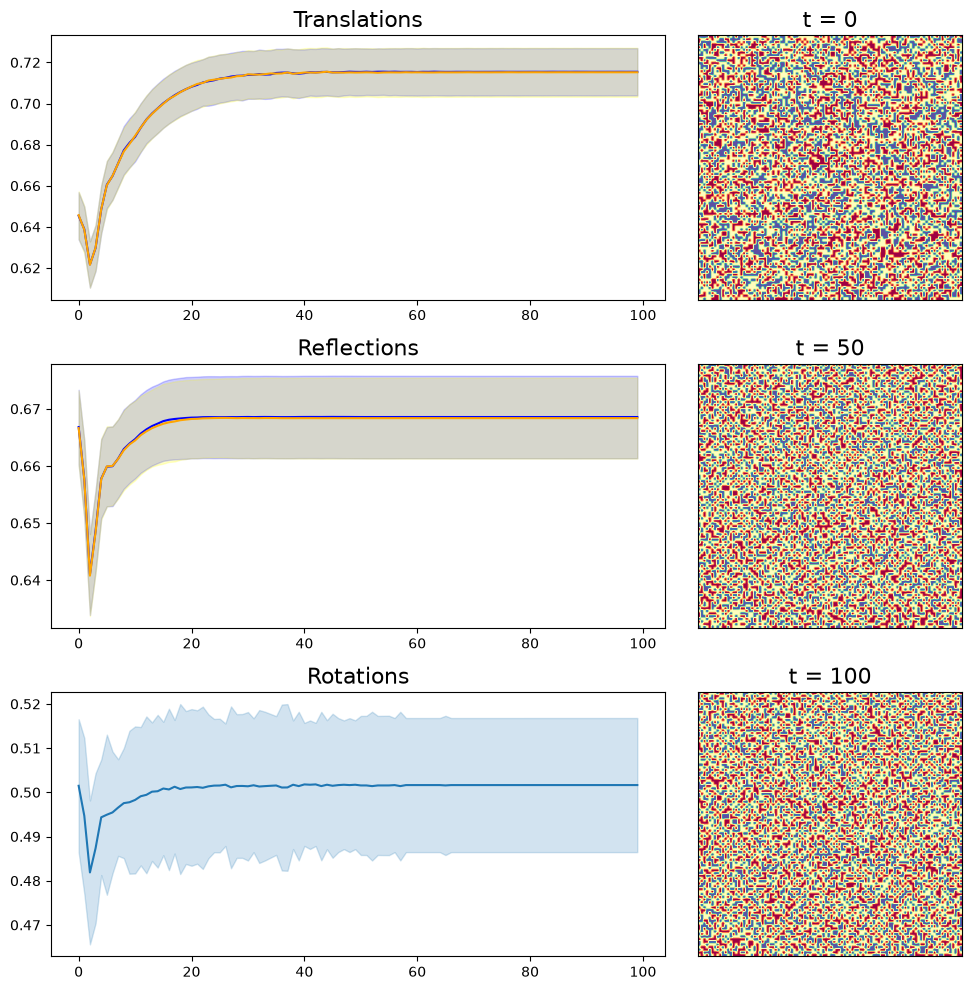

In [2]:
fig = plt.figure(figsize=(10, 10))
layout = fig.add_gridspec(3, 3)

# Each entry specifies the archive row, line colour, and band colour.
panels = (
    ("Translations", ((0, "blue", "blue"), (1, "orange", "yellow"))),
    ("Reflections", ((2, "blue", "blue"), (3, "orange", "yellow"))),
    ("Rotations", ((4, "tab:blue", "tab:blue"),)),
)

for row, (title, series) in enumerate(panels):
    ax = fig.add_subplot(layout[row, :2])
    ax.set_title(title, fontsize=16)

    for index, line_colour, band_colour in series:
        ax.plot(time, mean[index], color=line_colour)
        ax.fill_between(
            time,
            mean[index] - std[index],
            mean[index] + std[index],
            color=band_colour,
            alpha=0.2,
        )

    step = snapshot_steps[row]
    ax_snapshot = fig.add_subplot(layout[row, 2])
    ax_snapshot.imshow( 
        snapshots[step].astype(float),
        cmap="Spectral",
        vmin=0,
        vmax=2,
        interpolation="hanning",
        interpolation_stage="data",
    )
    ax_snapshot.set_title(f"t = {step}", fontsize=16)
    ax_snapshot.set_xticks([])
    ax_snapshot.set_yticks([])

fig.tight_layout()
plt.show()